In [1]:
import sys, os
sys.path.insert(0, os.path.abspath('..'))
from plot_config import COLORS, FIG_W_SINGLE, FIG_W_DOUBLE, set_font_size
GRID = False
FONT_SIZE = 18
set_font_size(FONT_SIZE)

In [2]:
import numpy as np
import matplotlib.pyplot as plt

d = np.load('outputs/fixed_gauss/fixed_gauss5.npz', allow_pickle=True)
t         = d['t']
k_params  = d['k_params']    # (n, 3)  — [lin_seg3, gauss_seg1, gauss_seg2]
comp_pos  = d['comp_pos']    # (n, 3, 3) — FK x/y/z at each VC s_param
goal      = d['goal']        # (n, 3, 3) — reference positions
names     = [str(s) for s in d['comp_names']]
s_params  = list(d['comp_s_params'])

print('Components:', list(zip(names, [f's={s:.3f}' for s in s_params])))
print('Duration:  ', f'{t[-1]:.1f} s')

# Find the gaussian strength drop (700->0 and 600->0)
gauss_k  = k_params[:, 1]
diff_k   = np.diff(gauss_k)
drop_idx = int(np.where(diff_k < -50)[0][0])
drop_t   = t[drop_idx]
print(f'\nGauss strength drop at t = {drop_t:.2f} s  (idx={drop_idx})')
print(f'  k before: gauss1={k_params[drop_idx, 1]:.0f}  gauss2={k_params[drop_idx, 2]:.0f}')
print(f'  k after:  gauss1={k_params[drop_idx+1, 1]:.0f}  gauss2={k_params[drop_idx+1, 2]:.0f}')

WIN = 5.0
mask_before = (t >= drop_t - WIN) & (t < drop_t)
mask_after  = (t >  drop_t)       & (t <= drop_t + WIN)
print(f'\nBefore window: {mask_before.sum()} samples  [{t[mask_before][0]:.2f}, {t[mask_before][-1]:.2f}] s')
print(f'After  window: {mask_after.sum()} samples  [{t[mask_after][0]:.2f}, {t[mask_after][-1]:.2f}] s')

Components: [('lin_seg3', 's=1.000'), ('gauss_seg1', 's=0.333'), ('gauss_seg2', 's=0.667')]
Duration:   63.9 s

Gauss strength drop at t = 53.40 s  (idx=16598)
  k before: gauss1=2100  gauss2=1800
  k after:  gauss1=0  gauss2=0

Before window: 1649 samples  [48.40, 53.39] s
After  window: 649 samples  [56.43, 58.40] s


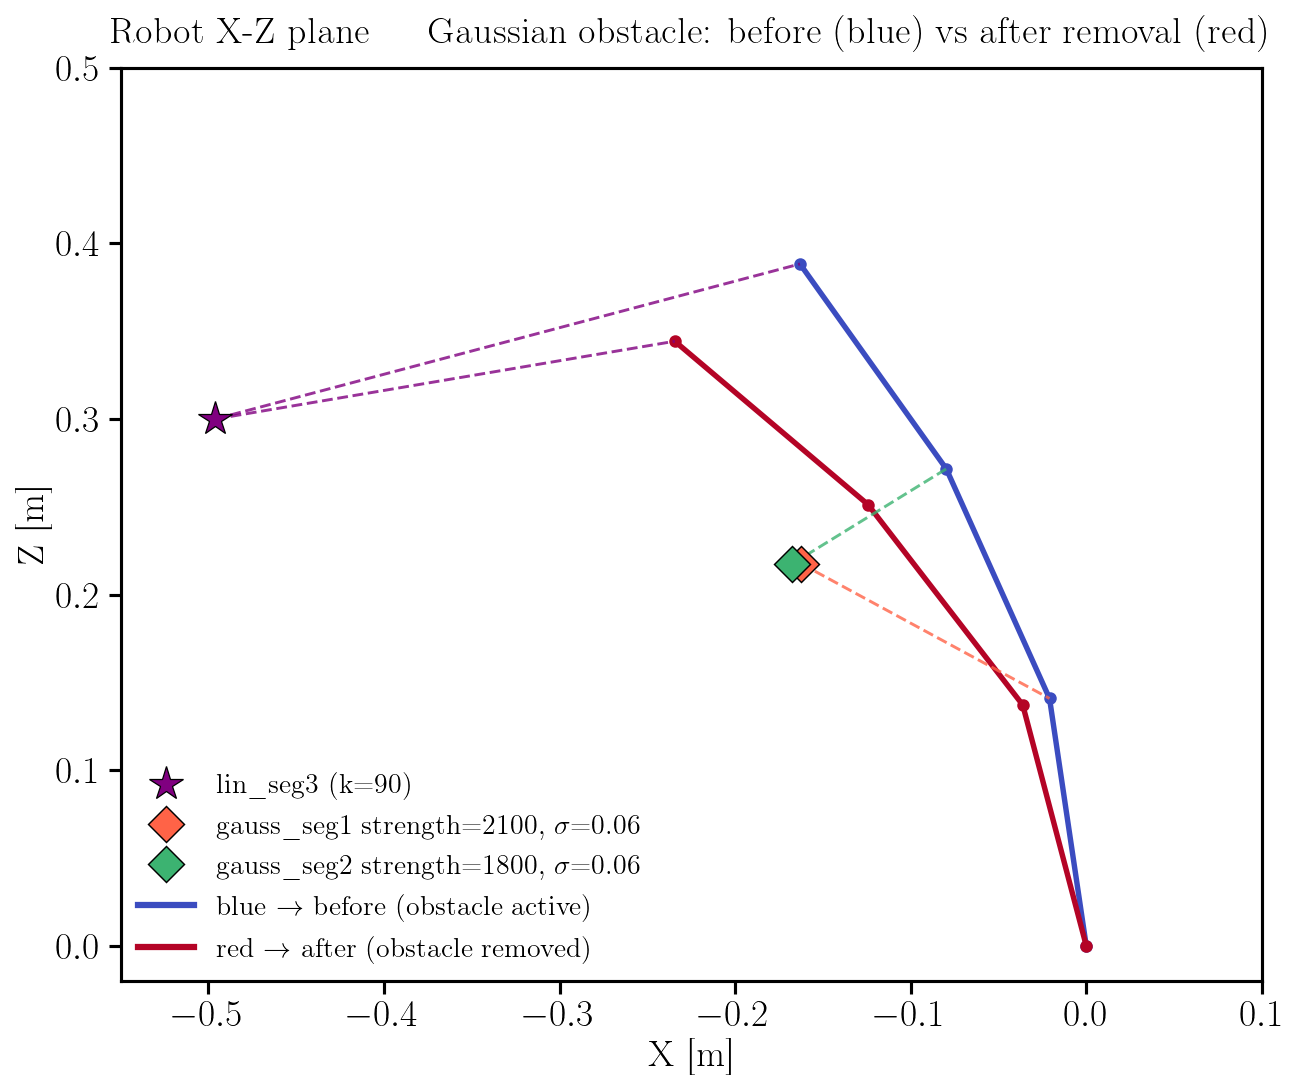

Saved -> outputs/fixed_gauss/fixed_gauss5_xz.pdf


In [3]:
# X-Z plane visualisation: before (blue) and after (red) — postures only
from matplotlib.lines import Line2D

VC_COLORS  = ['purple', 'tomato', 'mediumseagreen']  # lin, gauss1, gauss2
C_BEFORE   = '#3b4cc0'   # blue  (coolwarm low)
C_AFTER    = '#b40426'   # red   (coolwarm high)
BACKBONE_LW = 2.6

# Representative postures: mean position over each window
pose_before = comp_pos[mask_before].mean(axis=0)   # (3, 3)  [tip, g1, g2] x/y/z
pose_after  = comp_pos[mask_after].mean(axis=0)    # (3, 3)
gl_active   = goal[mask_before]                    # (m, 3, 3)

# Attach points (where the springs connect) — use the active (before) posture
attach_active = pose_before                        # (3, 3)

fig, ax = plt.subplots(figsize=(9, 8))

# ── Two backbones only: before (blue) and after (red) ────────────────────────
for pose, color in [(pose_before, C_BEFORE), (pose_after, C_AFTER)]:
    xs = [0.0, pose[1, 0], pose[2, 0], pose[0, 0]]   # origin -> s=1/3 -> s=2/3 -> tip
    zs = [0.0, pose[1, 2], pose[2, 2], pose[0, 2]]
    ax.plot(xs, zs, '-o', color=color, linewidth=BACKBONE_LW, markersize=5, zorder=3)

# ── Linear spring: dashed connectors ref(star) -> tip, for BEFORE and AFTER ──
lin_gx, lin_gz = float(gl_active[-1, 0, 0]), float(gl_active[-1, 0, 2])
ax.plot([lin_gx, pose_before[0, 0]], [lin_gz, pose_before[0, 2]],
        '--', color=VC_COLORS[0], linewidth=1.4, alpha=0.8, zorder=4)
ax.plot([lin_gx, pose_after[0, 0]], [lin_gz, pose_after[0, 2]],
        '--', color=VC_COLORS[0], linewidth=1.4, alpha=0.8, zorder=4)
lin_k = float(k_params[mask_before][0, 0])
ax.plot(lin_gx, lin_gz, '*', color=VC_COLORS[0], markersize=17,
        markeredgecolor='k', markeredgewidth=0.6, zorder=5,
        label=f'lin_seg3  (k={lin_k:.0f})')

# ── Gaussian springs: dashed connector ref(diamond) -> attach, + diamond ─────
for vc_i, color, prefix in [(1, VC_COLORS[1], 'gauss_seg1'),
                            (2, VC_COLORS[2], 'gauss_seg2')]:
    gx, gz = float(gl_active[0, vc_i, 0]), float(gl_active[0, vc_i, 2])
    ax.plot([gx, attach_active[vc_i, 0]], [gz, attach_active[vc_i, 2]],
            '--', color=color, linewidth=1.4, alpha=0.8, zorder=4)
    k_val = float(k_params[mask_before][0, vc_i])
    ax.plot(gx, gz, 'D', color=color, markersize=12,
            markeredgecolor='k', markeredgewidth=0.7, zorder=5,
            label=f'{prefix}  strength={k_val:.0f}, σ=0.06')

# ── Legend: 3 markers + blue/red (before/after) note in the same box ─────────
before_after = [
    Line2D([0], [0], color=C_BEFORE, lw=3, label='blue → before (obstacle active)'),
    Line2D([0], [0], color=C_AFTER,  lw=3, label='red → after (obstacle removed)'),
]
handles, _ = ax.get_legend_handles_labels()
ax.legend(handles=handles + before_after,
          loc='lower left', framealpha=0.92)

ax.set_xlabel('X  [m]')
ax.set_ylabel('Z  [m]')
ax.set_title('Robot X-Z plane — Gaussian obstacle: before (blue) vs after removal (red)')
ax.grid(GRID)
ax.set_xlim(-0.55, 0.10)
ax.set_ylim(-0.02, 0.50)
ax.set_aspect('equal')

plt.tight_layout()
out = os.path.join('outputs', 'fixed_gauss', 'fixed_gauss5_xz.pdf')
plt.savefig(out)
plt.show()
print(f'Saved -> {out}')